# Problema 2: Regressão Logística (Diagnóstico Cardíaco)

Classificação do risco de cardiopatia a partir de variáveis clínicas:
- `target`: Diagnóstico (0 = ausência, 1 = presença de cardiopatia) -> Variável alvo
- Atributos principais e unidades:
  - `age`: Idade (anos)
  - `sex`: Sexo (1 = masc., 0 = fem.)
  - `cp`: Tipo de dor torácica (1: angina típica, 2: atípica, 3: não anginosa, 4: assintomática)
  - `trestbps`: Pressão arterial em repouso (mm Hg)
  - `chol`: Colesterol sérico (mg/dl)
  - `fbs`: Açúcar no sangue em jejum > 120 mg/dl (1 = verdadeiro, 0 = falso)
  - `restecg`: Eletrocardiograma em repouso (0, 1, 2)
  - `thalach`: Frequência cardíaca máxima atingida (bpm)
  - `exang`: Angina induzida por exercício (1 = sim, 0 = não)
  - `oldpeak`: Depressão do segmento ST induzida por esforço (mm)
  - `slope`: Inclinação do segmento ST de pico no esforço (1, 2, 3)
  - `ca`: Número de vasos principais corados por fluoroscopia (0 a 3)
  - `thal`: Cintilografia miocárdica (3 = normal, 6 = defeito fixo, 7 = defeito reversível)


### 1. Importação das Bibliotecas

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, roc_auc_score, confusion_matrix
)

os.makedirs('graficos', exist_ok=True)


### 2. Carregamento dos Dados e Pré-processamento

In [2]:
dados = pd.read_csv('dataset/heart_cleveland.csv')
print(f"Total de pacientes: {dados.shape[0]} | Atributos: {dados.shape[1]}")
dados.head()


Total de pacientes: 303 | Atributos: 14


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


#### Identificação e Tratamento de Valores Ausentes
As colunas `ca` e `thal` possuem valores faltantes identificados originalmente pelo caractere `'?'`. Convertemos para numérico e imputamos pela mediana para preservar todos os 303 pacientes.


In [3]:
dados['ca'] = pd.to_numeric(dados['ca'], errors='coerce')
dados['thal'] = pd.to_numeric(dados['thal'], errors='coerce')

print("Valores ausentes identificados:")
print(f"- 'ca': {dados['ca'].isnull().sum()} ausentes")
print(f"- 'thal': {dados['thal'].isnull().sum()} ausentes")

dados['ca'] = dados['ca'].fillna(dados['ca'].median())
dados['thal'] = dados['thal'].fillna(dados['thal'].median())
print("Imputação pela mediana concluída com sucesso!")


Valores ausentes identificados:
- 'ca': 4 ausentes
- 'thal': 2 ausentes
Imputação pela mediana concluída com sucesso!


#### Binarização da Variável Alvo (`target`)
O diagnóstico original varia de 0 a 4. Binarizamos:
- **0**: Ausência de doença cardíaca
- **1**: Presença de doença cardíaca (níveis 1 a 4)


In [4]:
dados['target'] = (dados['target'] > 0).astype(int)
contagem = dados['target'].value_counts()
print(f"Classe 0 (Sem doença): {contagem[0]} ({contagem[0]/len(dados)*100:.1f}%)")
print(f"Classe 1 (Com doença): {contagem[1]} ({contagem[1]/len(dados)*100:.1f}%)")


Classe 0 (Sem doença): 164 (54.1%)
Classe 1 (Com doença): 139 (45.9%)


### 3. Divisão Treino/Teste e Padronização
Realizamos divisão estratificada 80% treino (242) e 20% teste (61) para manter a proporção de doentes, seguida de padronização Z-score.


In [5]:
X = dados.drop(columns=['target'])
y = dados['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

escalonador = StandardScaler()
X_train_pad = escalonador.fit_transform(X_train)
X_test_pad = escalonador.transform(X_test)
print(f"Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")


Treino: 242 amostras | Teste: 61 amostras


### 4. Tarefa 1: Treinamento com solver='liblinear'
Hiperparâmetros fixados: `solver='liblinear'`, `random_state=42`, `max_iter=1000`.


In [6]:
modelo = LogisticRegression(solver='liblinear', random_state=42, max_iter=1000)
modelo.fit(X_train_pad, y_train)

iteracoes = modelo.n_iter_[0]
print(f"Número de iterações para convergir: {iteracoes}")


Número de iterações para convergir: 5


**Por que convergiu em apenas 5 iterações?**  
O solver `liblinear` utiliza descida de coordenadas (*Coordinate Descent*). Como a base tem tamanho reduzido (242 amostras no treino) e os dados foram bem condicionados pela padronização Z-score, a perda logarítmica atinge o ponto de mínimo rapidamente.


### 5. Tarefa 2: Avaliação no Conjunto de Teste (20%)

In [7]:
y_pred = modelo.predict(X_test_pad)
y_prob = modelo.predict_proba(X_test_pad)[:, 1]

acuracia = accuracy_score(y_test, y_pred)
precisao = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print(f"Acurácia : {acuracia:.4f} ({acuracia*100:.2f}%)")
print(f"Precisão : {precisao:.4f} ({precisao*100:.2f}%)")
print(f"Recall   : {recall:.4f} ({recall*100:.2f}%)")
print(f"F1-score : {f1:.4f} ({f1*100:.2f}%)")
print(f"AUC (ROC): {auc:.4f}")


Acurácia : 0.8689 (86.89%)
Precisão : 0.8125 (81.25%)
Recall   : 0.9286 (92.86%)
F1-score : 0.8667 (86.67%)
AUC (ROC): 0.9513


#### Gráfico: Curva ROC (Receiver Operating Characteristic)
Avaliamos a capacidade discriminativa do modelo em múltiplos limiares de decisão.


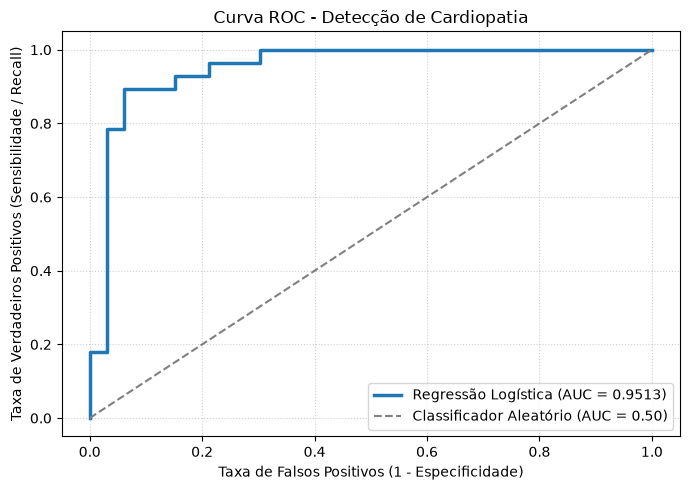

In [8]:
fpr, tpr, limiares = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'Regressão Logística (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Classificador Aleatório (AUC = 0.50)')
plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)')
plt.ylabel('Taxa de Verdadeiros Positivos (Sensibilidade / Recall)')
plt.title('Curva ROC - Detecção de Cardiopatia')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('graficos/curva_roc.png', dpi=300)
plt.show()


#### Gráfico: Matriz de Confusão
Analisamos a quantidade de verdadeiros positivos, verdadeiros negativos, falsos positivos e falsos negativos.


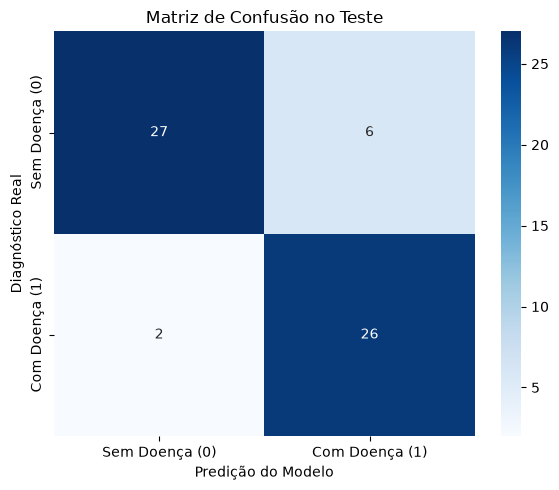

In [9]:
matriz = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Sem Doença (0)', 'Com Doença (1)'],
            yticklabels=['Sem Doença (0)', 'Com Doença (1)'])
plt.xlabel('Predição do Modelo')
plt.ylabel('Diagnóstico Real')
plt.title('Matriz de Confusão no Teste')
plt.tight_layout()
plt.savefig('graficos/matriz_confusao.png', dpi=300)
plt.show()


#### Análise de Relevância dos Fatores de Risco
Inspecionamos os coeficientes aprendidos pela regressão logística.


In [10]:
coefs = pd.Series(modelo.coef_[0], index=X.columns).sort_values()
print("Top 3 fatores que mais aumentam a probabilidade de doença:")
for k, v in coefs.tail(3).items():
    print(f"- {k}: coeficiente = +{v:.4f}")

print("\nTop 3 fatores associados à proteção (ausência de doença):")
for k, v in coefs.head(3).items():
    print(f"- {k}: coeficiente = {v:.4f}")


Top 3 fatores que mais aumentam a probabilidade de doença:
- sex: coeficiente = +0.6557
- thal: coeficiente = +0.6784
- ca: coeficiente = +1.1085

Top 3 fatores associados à proteção (ausência de doença):
- thalach: coeficiente = -0.3484
- fbs: coeficiente = -0.2205
- age: coeficiente = -0.1035


### Conclusão e Discussão Clínica
1. **Prioridade ao Recall ($92.86\%$):** No diagnóstico médico, um **Falso Negativo** (liberar um paciente infartado sem medicação) é potencialmente fatal. O modelo capturou 26 dos 28 pacientes cardiopatas do teste, gerando apenas 2 falsos negativos.
2. **AUC de $0.9513$:** Mostra excelente separação entre saudáveis e doentes.
3. **Concordância Médica:** O número de vasos obstruídos (`ca`), defeito de perfusão no tálio (`thal`) e sexo masculino (`sex`) despontam como os maiores preditores de risco, enquanto alta capacidade aeróbica (`thalach`) é o maior fator de proteção.
